In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.dates as mdates
import statsmodels.formula.api as smf
%matplotlib inline 


#load data (relative path after downloading directly from github)
#file_path = "/Second-Hand-Clothing-and-Textile-Waste-in-Accra/data/merged/Master_Merged_Analysis_Data 20260909.xlsx"


# Loading data (absolute path)
file_path = "/Users/talia/Desktop/Meital's task/remote sensing paper/resubmission/Master_Merged_Analysis_Data 20260909.xlsx" 
#the excel sheet name that contains all required data for further analysis
sheet = "All land fills night"
df_cleaned = pd.read_excel(file_path, sheet_name=sheet, header=1)


# Fix Variable Names & Dates
COL_WEIGHT = "net_weight_kg"
COL_VALUE = "trade_value_usd"
COL_PRICE = "Price_Per_Kg"
COL_FIRES = "Landfill_Fires"

# Convert the main price column to float, turning any text errors into NaN
df_cleaned['Price_Per_Kg'] = pd.to_numeric(df_cleaned['Price_Per_Kg'], errors='coerce')

/var/folders/_q/s5r46m0n1_gfj7k66zh2rnt80000gn/T/ipykernel_60252/1503139957.py:26: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_yearly_price = df_cleaned.groupby('year').apply(


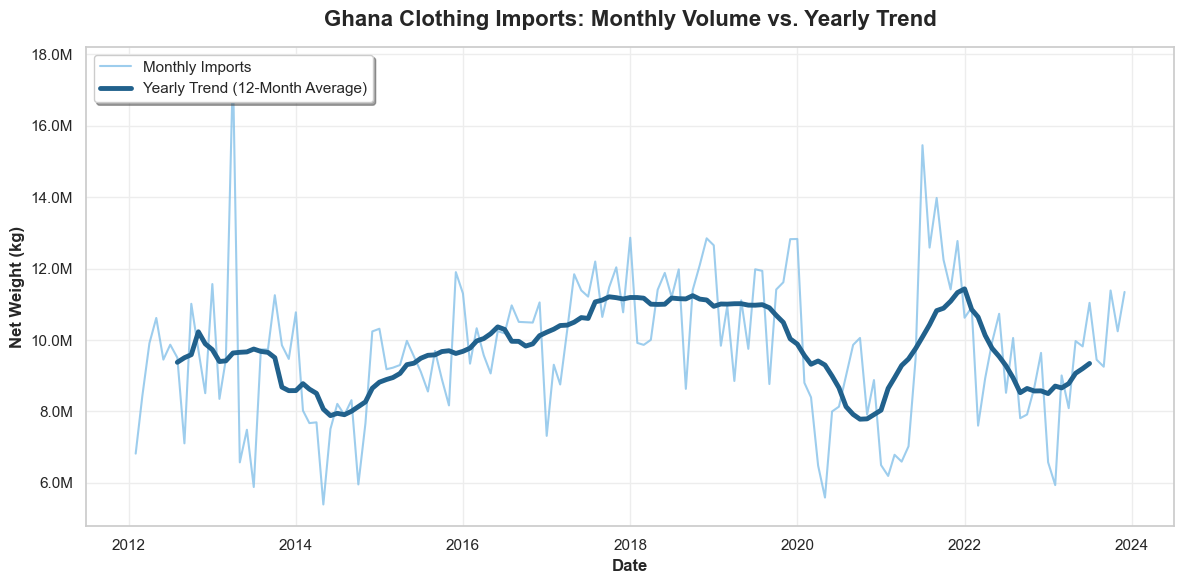

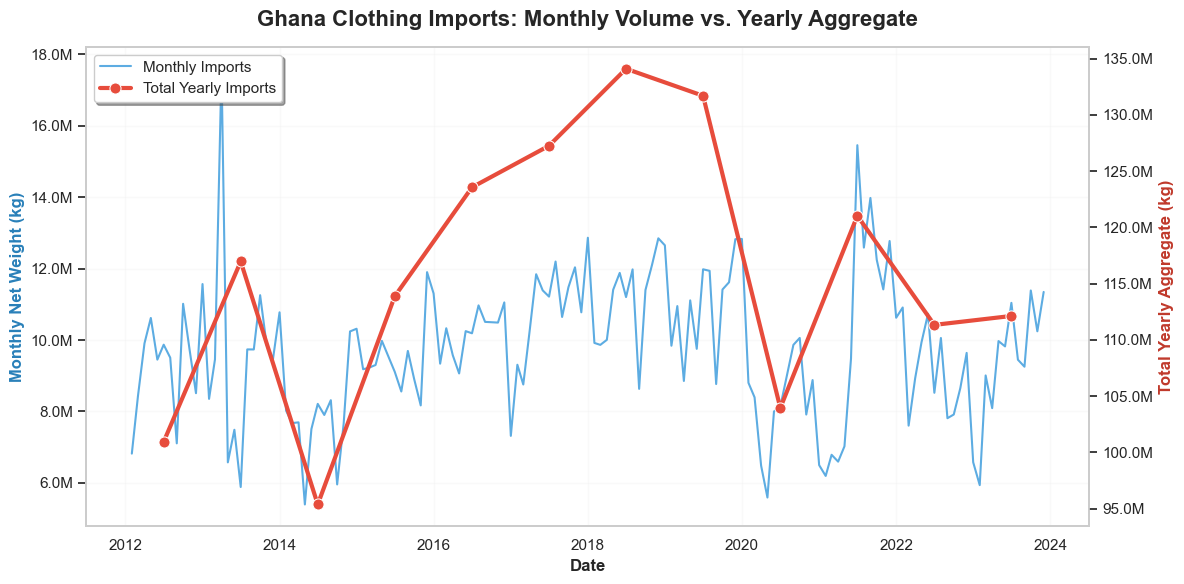

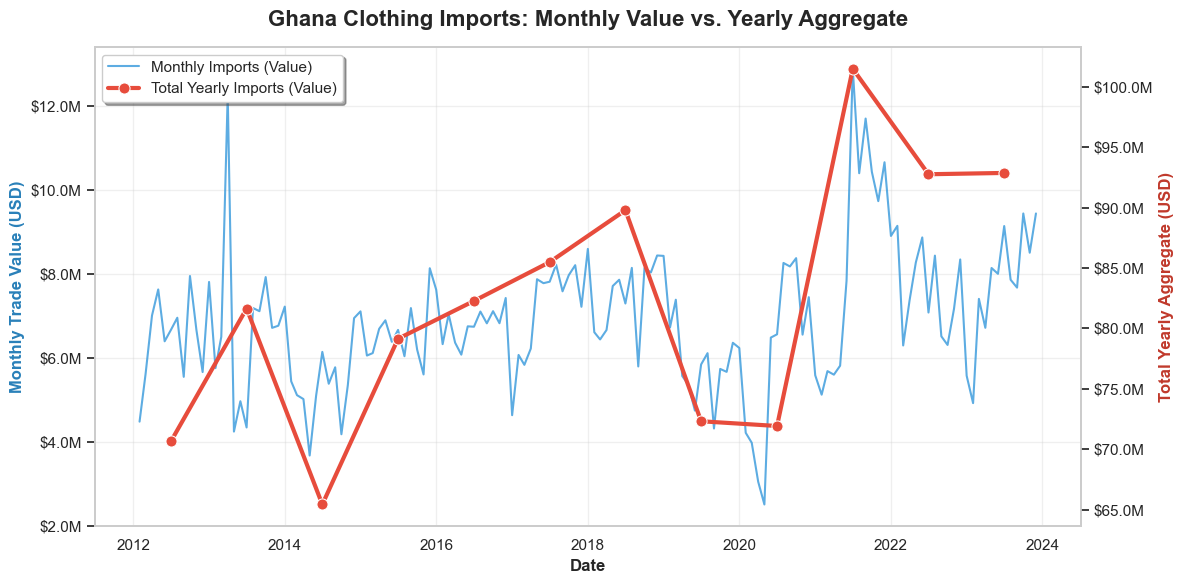

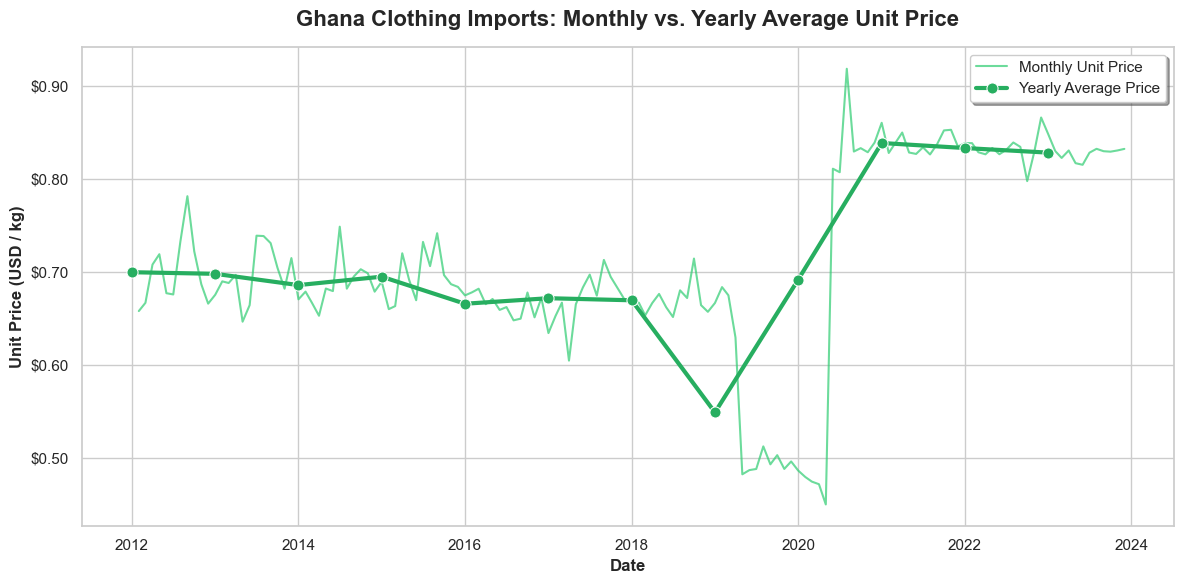

In [4]:
# ==========================================
# VISUALIZATIONS CODE
# ==========================================

# DATA PREP FOR GRAPHS
# Convert 'Month_Key' (e.g., '2012-02') to standard datetime for smooth plotting
df_cleaned['date'] = pd.to_datetime(df_cleaned['Month_Key'])

# Drop blank rows
df_cleaned.dropna(subset=['date'], inplace=True)
# convert year to a strict integer (remove the .0)
df_cleaned['year'] = df_cleaned['date'].dt.year.astype(int)
# chronological ordering
df_cleaned = df_cleaned.sort_values(by='date').reset_index(drop=True)
# fill blank fires with 0
df_cleaned[COL_FIRES] = df_cleaned[COL_FIRES].fillna(0)

# 12-Month Rolling Trend (Weight)
df_cleaned['yearly_trend'] = df_cleaned[COL_WEIGHT].rolling(window=12, center=True).mean()

# Yearly Aggregate Sum (Anchored to July 1 for visual centering)
df_yearly_agg = df_cleaned.groupby('year')[COL_WEIGHT].sum().reset_index()
df_yearly_agg['midpoint_date'] = pd.to_datetime(df_yearly_agg['year'].astype(str) + '-07-01')

# Yearly Average Price (Anchored to Jan 1)
df_yearly_price = df_cleaned.groupby('year').apply(
    lambda x: x[COL_VALUE].sum() / x[COL_WEIGHT].sum()
).reset_index(name='yearly_price')
df_yearly_price['start_date'] = pd.to_datetime(df_yearly_price['year'].astype(str) + '-01-01')

# Yearly Aggregate for value
df_yearly_agg_value = df_cleaned.groupby('year')[COL_VALUE].sum().reset_index()
df_yearly_agg_value['midpoint_date'] = pd.to_datetime(df_yearly_agg_value['year'].astype(str) + '-07-01') 

# =========================================================
# GRAPH 1: Monthly vs Yearly Trend
# =========================================================
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid", rc={"axes.facecolor": "white", "grid.color": "#ededed"})
sns.lineplot(data=df_cleaned, x='date', y=COL_WEIGHT, color="#85c1e9", linewidth=1.5, alpha=0.8, label="Monthly Imports")
sns.lineplot(data=df_cleaned, x='date', y='yearly_trend', color="#21618c", linewidth=3.5, label="Yearly Trend (12-Month Average)")

plt.title("Ghana Clothing Imports: Monthly Volume vs. Yearly Trend", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Date", fontsize=12, fontweight='bold')
plt.ylabel("Net Weight (kg)", fontsize=12, fontweight='bold')
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x * 1e-6:.1f}M'))
plt.legend(loc='upper left', frameon=True, shadow=True)
plt.tight_layout()
plt.show()


# =========================================================
# GRAPH 2: Dual-Axis Monthly vs Yearly Aggregate (Weight)
# =========================================================
fig, ax1 = plt.subplots(figsize=(12, 6))
sns.set_theme(style="whitegrid", rc={"axes.facecolor": "white"})

sns.lineplot(data=df_cleaned, x='date', y=COL_WEIGHT, ax=ax1, color="#3498db", linewidth=1.5, alpha=0.8, label="Monthly Imports")
ax2 = ax1.twinx()
sns.lineplot(data=df_yearly_agg, x='midpoint_date', y=COL_WEIGHT, ax=ax2, color="#e74c3c", linewidth=3, marker="o", markersize=8, label="Total Yearly Imports")

plt.title("Ghana Clothing Imports: Monthly Volume vs. Yearly Aggregate", fontsize=16, fontweight='bold', pad=15)
ax1.set_xlabel("Date", fontsize=12, fontweight='bold')
ax1.set_ylabel("Monthly Net Weight (kg)", fontsize=12, fontweight='bold', color="#2980b9")
ax2.set_ylabel("Total Yearly Aggregate (kg)", fontsize=12, fontweight='bold', color="#c0392b")

ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x * 1e-6:.1f}M'))
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x * 1e-6:.1f}M'))

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', frameon=True, shadow=True)
ax2.get_legend().remove()
ax1.grid(True, alpha=0.3)
ax2.grid(False)
plt.tight_layout()
plt.show()


# =========================================================
# GRAPH 3: Dual-Axis Monthly VALUE vs Yearly Aggregate
# =========================================================
fig, ax1 = plt.subplots(figsize=(12, 6))
sns.set_theme(style="whitegrid", rc={"axes.facecolor": "white"})

sns.lineplot(data=df_cleaned, x='date', y=COL_VALUE, ax=ax1, color="#3498db", linewidth=1.5, alpha=0.8, label="Monthly Imports (Value)")
ax2 = ax1.twinx()
sns.lineplot(data=df_yearly_agg_value, x='midpoint_date', y=COL_VALUE, ax=ax2, color="#e74c3c", linewidth=3, marker="o", markersize=8, label="Total Yearly Imports (Value)")

plt.title("Ghana Clothing Imports: Monthly Value vs. Yearly Aggregate", fontsize=16, fontweight='bold', pad=15)
ax1.set_xlabel("Date", fontsize=12, fontweight='bold')
ax1.set_ylabel("Monthly Trade Value (USD)", fontsize=12, fontweight='bold', color="#2980b9")
ax2.set_ylabel("Total Yearly Aggregate (USD)", fontsize=12, fontweight='bold', color="#c0392b")

ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'${x * 1e-6:.1f}M'))
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'${x * 1e-6:.1f}M'))

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', frameon=True, shadow=True)
ax2.get_legend().remove()
ax1.grid(True, alpha=0.3)
ax2.grid(False)
plt.tight_layout()
plt.show()


# =========================================================
# GRAPH 4: Unit Price (Monthly vs Yearly Average)
# =========================================================
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid", rc={"axes.facecolor": "white"})

sns.lineplot(data=df_cleaned, x='date', y=COL_PRICE, color="#2ecc71", linewidth=1.5, alpha=0.7, label="Monthly Unit Price")
sns.lineplot(data=df_yearly_price, x='start_date', y='yearly_price', color="#27ae60", linewidth=3, marker="o", markersize=8, label="Yearly Average Price")

plt.title("Ghana Clothing Imports: Monthly vs. Yearly Average Unit Price", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Date", fontsize=12, fontweight='bold')
plt.ylabel("Unit Price (USD / kg)", fontsize=12, fontweight='bold')
plt.gca().yaxis.set_major_formatter(ticker.FormatStrFormatter('$%1.2f'))
plt.legend(loc='upper right', frameon=True, shadow=True)
plt.tight_layout()
plt.show()


  OLS MODEL 1: AVG IMPORT WEIGHT (LOG) VS LOG(FIRE AVG)  

Window   N  Zero Count   Coef  HAC SE        HAC 95% CI  Std P-Val Std Sig  HAC P-Val HAC Sig     R2
  1-Mo 143          47 0.9219  0.7162 [-0.4817, 2.3256]     0.1564      No     0.1980      No 0.0142
  2-Mo 142          26 0.7417  0.8051 [-0.8363, 2.3197]     0.2475      No     0.3569      No 0.0095
  3-Mo 141          14 0.7744  0.8649 [-0.9208, 2.4696]     0.2080      No     0.3706      No 0.0114
  4-Mo 140           6 1.0721  0.9225 [-0.7359, 2.8801]     0.0721      No     0.2451      No 0.0233
  5-Mo 139           2 1.3280  0.9881 [-0.6086, 3.2646]     0.0255       *     0.1790      No 0.0359
  6-Mo 138           1 1.5967  1.0438 [-0.4492, 3.6425]     0.0077      **     0.1261      No 0.0511
  7-Mo 137           0 1.9077  1.0869 [-0.2226, 4.0380]     0.0013      **     0.0792      No 0.0736
  8-Mo 136           0 2.1627  1.1379 [-0.0675, 4.3930]     0.0003     ***     0.0573      No 0.0940
  9-Mo 135           0 2.3501  

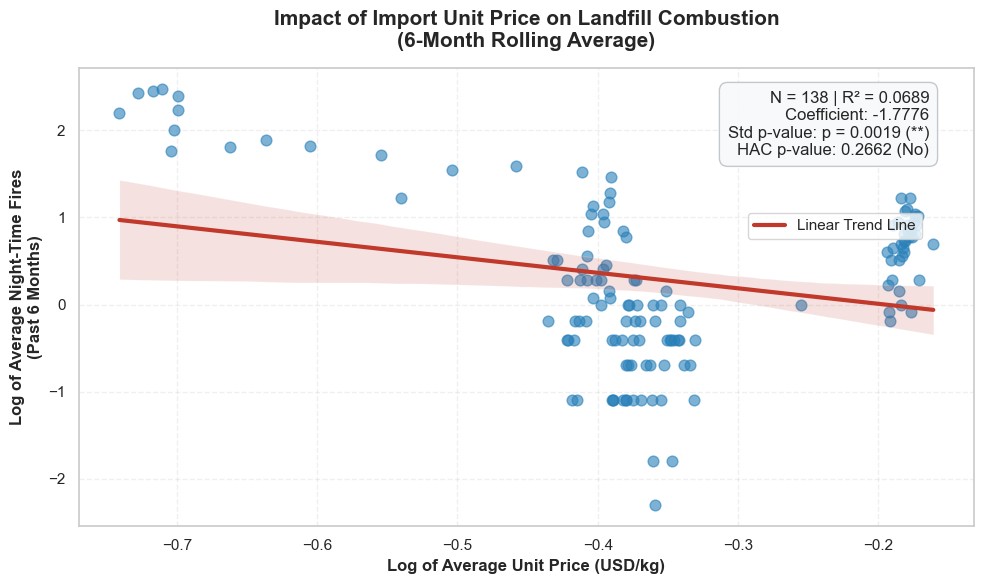

In [10]:
# ==========================================
# OLS REGRESSION ANALYSIS & SCATTERPLOT (STD + HAC)
# ==========================================

# ==========================================
# REGRESSION CONTROL PANEL
# ==========================================
USE_LOG_FIRE = True
USE_LOG_PRICE = True
# ==========================================

if COL_FIRES not in df_cleaned.columns:
    print("Warning: Fire column 'Landfill_Fires' not found. Cannot run regressions.")
else:
    results_weight = []
    results_price = []
    results_lag = []
    windows = range(1, 13)

    for w in windows:
        df_temp = df_cleaned.copy()

        # Calculate Rolling averages
        df_temp['Fire_Avg'] = df_temp[COL_FIRES].rolling(window=w).mean()
        df_temp['Price_Avg'] = df_temp[COL_PRICE].rolling(window=w).mean()
        df_temp['Weight_Avg']=df_temp[COL_WEIGHT].rolling(window=w).mean()

        # Count the zeros for this window
        zero_fires = (df_temp['Fire_Avg'] == 0).sum()
        
        # Apply Transformations (Replacing 0 with 0.1 for the log)
        df_temp['log_weight'] = np.log(df_temp['Weight_Avg'].replace(0, 0.1))

        if USE_LOG_FIRE:
            df_temp['y_fire'] = np.log(df_temp['Fire_Avg'].replace(0, 0.1))
            fire_label = "Log(Fire Avg)"
        else:
            df_temp['y_fire'] = df_temp['Fire_Avg']
            fire_label = "Fire Avg"

        if USE_LOG_PRICE:
            df_temp['x_price'] = np.log(df_temp['Price_Avg'].replace(0, 0.1))
            price_label = "Log(Price Avg)"
        else:
            df_temp['x_price'] = df_temp['Price_Avg']
            price_label = "Price Avg"

        # Drop standard NAs 
        df_temp.dropna(subset=['log_weight', 'x_price', 'y_fire'], inplace=True)
        
        if len(df_temp) > 20:
            try:
                def get_sig(p):
                    if p < 0.001: return "***"
                    elif p < 0.01: return "**"
                    elif p < 0.05: return "*"
                    else: return "No"

                # MODEL 1: Fires vs Log Weight
                mod_w_std = smf.ols('y_fire ~ log_weight', data=df_temp).fit()
                mod_w_hac = smf.ols('y_fire ~ log_weight', data=df_temp).fit(cov_type='HAC', cov_kwds={'maxlags': w})
                
                coef_w = mod_w_std.params.get('log_weight', np.nan)
                p_w_std = mod_w_std.pvalues.get('log_weight', np.nan)
                p_w_hac = mod_w_hac.pvalues.get('log_weight', np.nan)
                
                se_w_hac = mod_w_hac.bse.get('log_weight', np.nan)
                ci_w_hac = mod_w_hac.conf_int().loc['log_weight']
                
                # P-value formatting helper to replace 0.0 with < 0.001
                def fmt_p(p):
                    return "< 0.001" if p < 0.001 else f"{p:.4f}"

                results_weight.append({
                    'Window': f"{w}-Mo",
                    'N': int(mod_w_std.nobs),
                    'Zero Count': int(zero_fires),
                    'Coef': round(coef_w, 4),
                    'HAC SE': round(se_w_hac, 4),
                    'HAC 95% CI': f"[{ci_w_hac[0]:.4f}, {ci_w_hac[1]:.4f}]",
                    'Std P-Val': round(p_w_std, 4),
                    'Std Sig': get_sig(p_w_std),
                    'HAC P-Val': round(p_w_hac, 4),
                    'HAC Sig': get_sig(p_w_hac),
                    'R2': round(mod_w_std.rsquared, 4)
                })

                # MODEL 2: Fires vs Price
                mod_p_std = smf.ols('y_fire ~ x_price', data=df_temp).fit()
                mod_p_hac = smf.ols('y_fire ~ x_price', data=df_temp).fit(cov_type='HAC', cov_kwds={'maxlags': w})
                
                coef_p = mod_p_std.params.get('x_price', np.nan)
                p_p_std = mod_p_std.pvalues.get('x_price', np.nan)
                
                p_p_hac = mod_p_hac.pvalues.get('x_price', np.nan)
                se_p_hac = mod_p_hac.bse.get('x_price', np.nan)
                ci_p_hac = mod_p_hac.conf_int().loc['x_price']

                results_price.append({
                    'Window': f"{w}-Mo",
                    'N': int(mod_p_std.nobs),
                    #'Zero Count': int(zero_fires),
                    'Coef': round(coef_p, 4),
                    'HAC SE': round(se_p_hac, 4),
                    'HAC 95% CI': f"[{ci_p_hac[0]:.4f}, {ci_p_hac[1]:.4f}]",
                    'Std P-Val': fmt_p(p_p_std),
                    'HAC P-Val': round(p_p_hac, 4),
                    'HAC Sig': get_sig(p_p_hac),
                    'R2': round(mod_p_std.rsquared, 4)
                })
            except Exception as e:
                pass

    # --- PRINT OLS RESULT TABLES ---
    print("\n=========================================================================")
    print(f"  OLS MODEL 1: AVG IMPORT WEIGHT (LOG) VS {fire_label.upper()}  ")
    print("=========================================================================\n")
    print(pd.DataFrame(results_weight).to_string(index=False))
    print("\n")

    print("=========================================================================")
    print(f"  OLS MODEL 2: {price_label.upper()} VS {fire_label.upper()} ")
    print("=========================================================================\n")
    print(pd.DataFrame(results_price).to_string(index=False))
    print("\n")
    
# --- EXPORT TO EXCEL ---
    excel_output_path = "ols_sensitivity_results.xlsx"
    with pd.ExcelWriter(excel_output_path, engine="openpyxl") as writer:
        pd.DataFrame(results_weight).to_excel(writer, sheet_name="Table_A3_Weight", index=False)
        pd.DataFrame(results_price).to_excel(writer, sheet_name="Table_A1_Price", index=False)

    print(f"Saved OLS result tables to '{excel_output_path}'")

# ==========================================
# DYNAMIC SCATTERPLOT (6-MONTH)
# ==========================================
w = 6
df_final = df_cleaned.copy()

df_final['Fire_Avg'] = df_final[COL_FIRES].rolling(window=w).mean()
df_final['Price_Avg'] = df_final[COL_PRICE].rolling(window=w).mean()

# Diagnostic print for the scatterplot
zero_fires_6m = (df_final['Fire_Avg'] == 0).sum()
#print(f"--- Generating Scatterplot (6-Month {fire_label} vs. {price_label}) ---")
print(f"--- Found {zero_fires_6m} instances of true 0s in the 6-month fire average ---")

DRAW_LOG_TRENDLINE = True

if USE_LOG_FIRE:
    df_final['y_fire'] = np.log(df_final['Fire_Avg'].replace(0, 0.1))
    y_axis_label = f'Log of Average Night-Time Fires\n(Past {w} Months)'
else:
    df_final['y_fire'] = df_final['Fire_Avg']
    y_axis_label = f'Average Night-Time Fires\n(Past {w} Months)'

if USE_LOG_PRICE:
    df_final['x_price'] = np.log(df_final['Price_Avg'].replace(0, 0.1))
    x_axis_label = 'Log of Average Unit Price (USD/kg)'
else:
    df_final['x_price'] = df_final['Price_Avg']
    x_axis_label = 'Average Unit Price (USD/kg)'

df_final.dropna(subset=['x_price', 'y_fire'], inplace=True)

if DRAW_LOG_TRENDLINE and not USE_LOG_PRICE:
    formula = 'y_fire ~ np.log(x_price)'
    model_std = smf.ols(formula, data=df_final).fit()
    model_hac = smf.ols(formula, data=df_final).fit(cov_type='HAC', cov_kwds={'maxlags': w})
    p_std = model_std.pvalues['np.log(x_price)']
    p_hac = model_hac.pvalues['np.log(x_price)']
    coef = model_std.params['np.log(x_price)']
    line_label = 'Logarithmic Trend Line'
    r2_label = 'Log Curve R²'
else:
    formula = 'y_fire ~ x_price'
    model_std = smf.ols(formula, data=df_final).fit()
    model_hac = smf.ols(formula, data=df_final).fit(cov_type='HAC', cov_kwds={'maxlags': w})
    p_std = model_std.pvalues['x_price']
    p_hac = model_hac.pvalues['x_price']
    coef = model_std.params['x_price']
    line_label = 'Linear Trend Line'
    r2_label = 'Standard R²'

r_squared = model_std.rsquared
r_val = np.sign(coef) * np.sqrt(r_squared)
n_obs = int(model_std.nobs)

plt.figure(figsize=(10, 6))
sns.regplot(
    x='x_price',
    y='y_fire',
    data=df_final,
    logx=DRAW_LOG_TRENDLINE if not USE_LOG_PRICE else False,
    scatter_kws={'color': '#2980b9', 's': 60, 'alpha': 0.6, 'label': 'Monthly Observations'},
    line_kws={'color': '#c0392b', 'linewidth': 3, 'label': line_label},
    ci=95
)

plt.title(f'Impact of Import Unit Price on Landfill Combustion\n({w}-Month Rolling Average)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel(x_axis_label, fontsize=12, fontweight='bold')
plt.ylabel(y_axis_label, fontsize=12, fontweight='bold')

sig_label_std = "***" if p_std < 0.001 else "**" if p_std < 0.01 else "*" if p_std < 0.05 else "No"
sig_label_hac = "***" if p_hac < 0.001 else "**" if p_hac < 0.01 else "*" if p_hac < 0.05 else "No"
p_formatted = "p < 0.001" if p_std < 0.001 else f"p = {p_std:.4f}"

text_str = (f"N = {n_obs} | R² = {r_squared:.4f}\n"
            f"Coefficient: {coef:.4f}\n"
            f"Std p-value: {p_formatted} ({sig_label_std})\n"
            f"HAC p-value: {p_hac:.4f} ({sig_label_hac})")

plt.gca().text(0.95, 0.95, text_str, transform=plt.gca().transAxes, fontsize=12,
               verticalalignment='top', horizontalalignment='right',
               bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', alpha=0.9, edgecolor='#bdc3c7'))

plt.legend(loc='upper right', bbox_to_anchor=(0.95, 0.70))
plt.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

In [18]:
# =========================================================================
# OLS MODEL 3: STANDALONE SIMPLE LAG ANALYSIS (ABSOLUTE VALUES)
# =========================================================================

results_lag = []
windows = range(1, 13)

for w in windows:
    df_lag = df_cleaned.copy()
    
    # Shift price forward by w months
    df_lag['Price_Lagged'] = df_lag['Price_Per_Kg'].shift(w)
    
    df_lag['y_fire_lag'] = pd.to_numeric(df_lag['Landfill_Fires'], errors='coerce')
    df_lag['x_price_lag'] = pd.to_numeric(df_lag['Price_Lagged'], errors='coerce')

    #  drop the empty rows created by the time-shift
    df_lag.dropna(subset=['x_price_lag', 'y_fire_lag'], inplace=True)
    
    if len(df_lag) > 20:
        mod_lag_std = smf.ols('y_fire_lag ~ x_price_lag', data=df_lag).fit()
        mod_lag_hac = smf.ols('y_fire_lag ~ x_price_lag', data=df_lag).fit(cov_type='HAC', cov_kwds={'maxlags': w})
        
        coef_lag = mod_lag_std.params.get('x_price_lag', np.nan)
        p_lag_std = mod_lag_std.pvalues.get('x_price_lag', np.nan)
        
        p_lag_hac = mod_lag_hac.pvalues.get('x_price_lag', np.nan)
        se_lag_hac = mod_lag_hac.bse.get('x_price_lag', np.nan)
        
        try:
            ci_lag_hac_vals = mod_lag_hac.conf_int().loc['x_price_lag']
            ci_str = f"[{ci_lag_hac_vals[0]:.4f}, {ci_lag_hac_vals[1]:.4f}]"
        except KeyError:
            ci_str = "[NaN, NaN]"
        
        def get_sig(p):
            if pd.isna(p): return "No"
            elif p < 0.001: return "***"
            elif p < 0.01: return "**"
            elif p < 0.05: return "*"
            else: return "No"

        # Append to our list
        results_lag.append({
            'Lag': f"{w}-Mo Lag",
            'N': int(mod_lag_std.nobs),
            'Coef': round(coef_lag, 4),
            'HAC SE': round(se_lag_hac, 4),
            'HAC 95% CI': ci_str,
            'Std P-Val': round(p_lag_std, 4),
            'HAC P-Val': round(p_lag_hac, 4),
            'HAC Sig': get_sig(p_lag_hac),
            'R2': round(mod_lag_std.rsquared, 4)
        })

print("\n=========================================================================")
print("  OLS MODEL 3: PRICE VS FIRE SIMPLE LAG (ABSOLUTE VALUES)")
print("=========================================================================\n")
print(pd.DataFrame(results_lag).to_string(index=False))
print("\n")


  OLS MODEL 3: PRICE VS FIRE SIMPLE LAG (ABSOLUTE VALUES)

      Lag   N     Coef  HAC SE         HAC 95% CI  Std P-Val  HAC P-Val HAC Sig     R2
 1-Mo Lag 142 -10.3472  5.3319 [-20.7975, 0.1031]     0.0000     0.0523      No 0.1160
 2-Mo Lag 141  -9.2292  6.1354 [-21.2544, 2.7960]     0.0003     0.1325      No 0.0915
 3-Mo Lag 140  -7.6488  6.4851 [-20.3593, 5.0618]     0.0030     0.2382      No 0.0622
 4-Mo Lag 139  -6.5150  6.8694 [-19.9788, 6.9488]     0.0123     0.3429      No 0.0448
 5-Mo Lag 138  -6.4235  7.1290 [-20.3960, 7.5491]     0.0144     0.3676      No 0.0432
 6-Mo Lag 137  -6.2199  7.6490 [-21.2116, 8.7718]     0.0188     0.4161      No 0.0402
 7-Mo Lag 136  -6.3513  6.7189 [-19.5201, 6.8176]     0.0171     0.3445      No 0.0417
 8-Mo Lag 135  -4.9314  5.1001 [-14.9274, 5.0645]     0.0675     0.3336      No 0.0249
 9-Mo Lag 134  -2.8944  2.8678  [-8.5152, 2.7265]     0.2890     0.3129      No 0.0085
10-Mo Lag 133  -0.2194  1.6473  [-3.4480, 3.0092]     0.9366     0.894

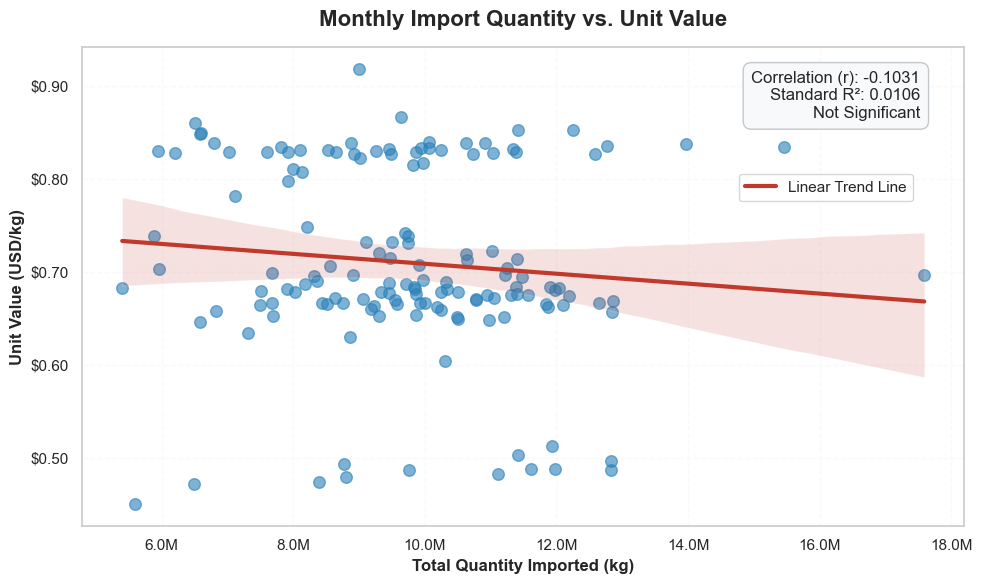

In [19]:
# ==========================================
# APPENDIX - PRICE ELASTICITY
# ==========================================
#make columns numeric 
df_appendix = df_cleaned.copy()
df_appendix[COL_WEIGHT] = pd.to_numeric(df_appendix[COL_WEIGHT], errors='coerce')
df_appendix[COL_PRICE] = pd.to_numeric(df_appendix[COL_PRICE], errors='coerce')

#Drop missing values just in case
df_appendix.dropna(subset=[COL_WEIGHT, COL_PRICE], inplace=True)


# Calculate Correlation and Fit Model for Stats Box
formula_elasticity = f"{COL_PRICE} ~ {COL_WEIGHT}"
model_elasticity = smf.ols(formula_elasticity, data=df_appendix).fit()

p_val_elast = model_elasticity.pvalues[COL_WEIGHT]
coef_elast = model_elasticity.params[COL_WEIGHT]
r_squared_elast = model_elasticity.rsquared
correlation = np.sign(coef_elast) * np.sqrt(r_squared_elast)

# Build Plot
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid", rc={"axes.facecolor": "white", "grid.color": "#ededed"})

sns.regplot(
    x=COL_WEIGHT,
    y=COL_PRICE,
    data=df_appendix,
    scatter_kws={'color': '#2980b9', 's': 70, 'alpha': 0.6, 'label': 'Monthly Observations'},
    line_kws={'color': '#c0392b', 'linewidth': 3, 'label': 'Linear Trend Line'},
    ci=95
)

# Dynamic Formatting
plt.title("Monthly Import Quantity vs. Unit Value", fontsize=16, fontweight='bold', pad=15)
plt.xlabel("Total Quantity Imported (kg)", fontsize=12, fontweight='bold')
plt.ylabel("Unit Value (USD/kg)", fontsize=12, fontweight='bold')

# Format X-axis to Millions (M) and Y-axis to Currency
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{x*1e-6:.1f}M'))
plt.gca().yaxis.set_major_formatter(ticker.FormatStrFormatter('$%1.2f'))

# Statistical Box 
sig_label_elast = "Significant (***)" if p_val_elast < 0.001 else "Significant (**)" if p_val_elast < 0.01 else "Significant (*)" if p_val_elast < 0.05 else "Not Significant"
text_str_elast = f"Correlation (r): {correlation:.4f}\nStandard R²: {r_squared_elast:.4f}\n{sig_label_elast}"

plt.gca().text(0.95, 0.95, text_str_elast, transform=plt.gca().transAxes, fontsize=12,
               verticalalignment='top', horizontalalignment='right',
               bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', alpha=0.9, edgecolor='#bdc3c7'))

# Adjust legend location
plt.legend(loc='upper right', bbox_to_anchor=(0.95, 0.75))
plt.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

--- Running Reviewer Robustness Checks (6-Month Window) ---

[TEST 1: Excluding 2019 & 2020]
Price Coefficient: 7.1130
P-Value: 0.0000 (Significant)

[TEST 2: With Year Fixed Effects (C(year))]
Price Coefficient: -26.1016
P-Value: 0.0000 (Significant)


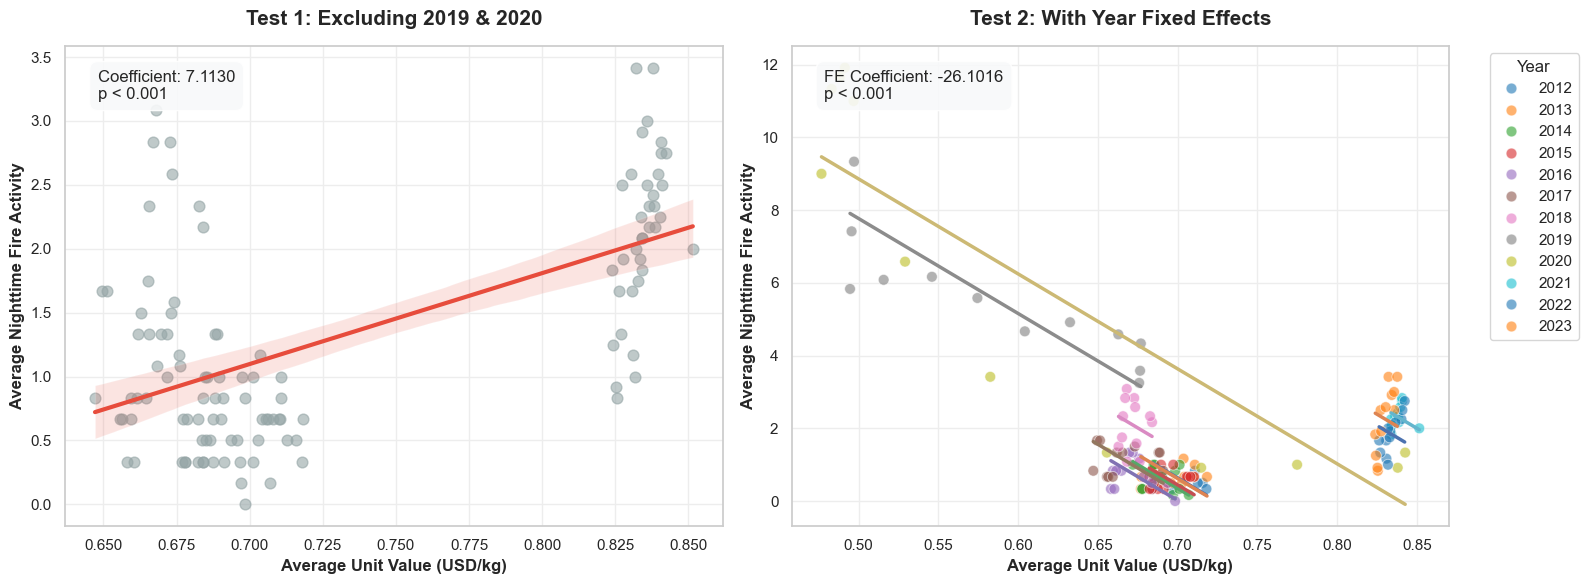

In [22]:
# ==========================================
# REVIEWER ROBUSTNESS CHECKS
# ==========================================
print("--- Running Reviewer Robustness Checks (6-Month Window) ---")

w = 6
df_robust = df_cleaned.copy()
df_robust['Fire_Avg'] = df_robust[COL_FIRES].rolling(window=w).mean()
df_robust['Price_Avg'] = df_robust[COL_PRICE].rolling(window=w).mean()

# Drop NaNs generated by rolling average
df_robust.dropna(subset=['Price_Avg', 'Fire_Avg'], inplace=True)

# ---------------------------------------------------------
# TEST 1: "Without 2019-2020" Model
# ---------------------------------------------------------
# Filter out the years 2019 and 2020
df_no_covid = df_robust[~df_robust['year'].isin([2019, 2020])]

mod_no_covid = smf.ols('Fire_Avg ~ Price_Avg', data=df_no_covid).fit()
p_val_1 = mod_no_covid.pvalues['Price_Avg']

print("\n[TEST 1: Excluding 2019 & 2020]")
print(f"Price Coefficient: {mod_no_covid.params['Price_Avg']:.4f}")
print(f"P-Value: {p_val_1:.4f} " + ("(Significant)" if p_val_1 < 0.05 else "(Not Significant)"))

#graphs for test 1
#graph style
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.set_theme(style="whitegrid", rc={"axes.facecolor": "white", "grid.color": "#ededed"})

#graph for test 1 - without 2019-2020
sns.regplot(
    x='Price_Avg', 
    y='Fire_Avg', 
    data=df_no_covid, 
    ax=axes[0],
    scatter_kws={'color': '#95a5a6', 'alpha': 0.6, 's': 60},
    line_kws={'color': '#e74c3c', 'linewidth': 3}
)

axes[0].set_title("Test 1: Excluding 2019 & 2020", fontsize=15, fontweight='bold', pad=15)
axes[0].set_xlabel("Average Unit Value (USD/kg)", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Average Nighttime Fire Activity", fontsize=12, fontweight='bold')

# Stats box for Graph 1
text_1 = f"Coefficient: {mod_no_covid.params['Price_Avg']:.4f}\np < 0.001"
axes[0].text(0.05, 0.95, text_1, transform=axes[0].transAxes, fontsize=12,
             verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', alpha=0.9))

# ---------------------------------------------------------
# TEST 2: Calendar-Year Fixed Effects
# ---------------------------------------------------------
# C(year): treat the 'year' column as a categorical control
mod_fe = smf.ols('Fire_Avg ~ Price_Avg + C(year)', data=df_robust).fit()
p_val_2 = mod_fe.pvalues['Price_Avg']

print("\n[TEST 2: With Year Fixed Effects (C(year))]")
print(f"Price Coefficient: {mod_fe.params['Price_Avg']:.4f}")
print(f"P-Value: {p_val_2:.4f} " + ("(Significant)" if p_val_2 < 0.05 else "(Not Significant)"))


# ---------------------------------------------------------
# GRAPH 2: Year Fixed Effects (Simpson's Paradox Visualization)
# ---------------------------------------------------------
# Calculate predicted values
df_robust['FE_Predict'] = mod_fe.predict()

sns.scatterplot(
    x='Price_Avg', 
    y='Fire_Avg', 
    hue='year', 
    palette='tab10', 
    data=df_robust, 
    ax=axes[1], 
    alpha=0.6, 
    s=60
)

# regression lines for each year
df_robust_sorted = df_robust.sort_values(['year', 'Price_Avg'])
for year in df_robust_sorted['year'].unique():
    subset = df_robust_sorted[df_robust_sorted['year'] == year]
    axes[1].plot(subset['Price_Avg'], subset['FE_Predict'], linewidth=2.5)

axes[1].set_title("Test 2: With Year Fixed Effects", fontsize=15, fontweight='bold', pad=15)
axes[1].set_xlabel("Average Unit Value (USD/kg)", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Average Nighttime Fire Activity", fontsize=12, fontweight='bold')

# Stats box for Graph 2
text_2 = f"FE Coefficient: {mod_fe.params['Price_Avg']:.4f}\np < 0.001"
axes[1].text(0.05, 0.95, text_2, transform=axes[1].transAxes, fontsize=12,
             verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', alpha=0.9))

# Move the legend outside the plot
axes[1].legend(title='Year', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()


[Year Fixed Effects WITHOUT 2019/2020]
Coefficient: 6.0251
P-Value: 0.1812 (Not Significant)


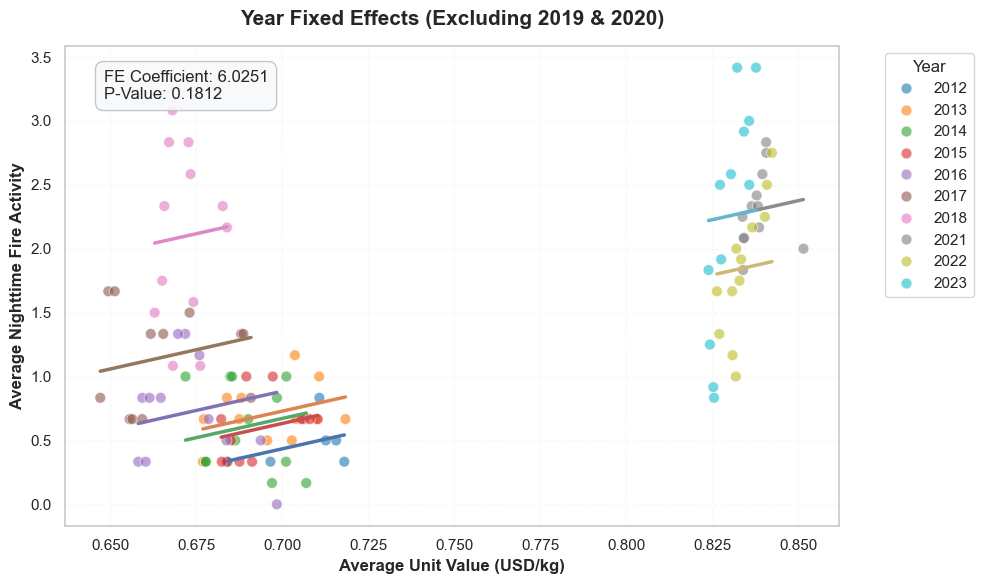

In [25]:
# ---------------------------------------------------------
# Further test: Fixed Effects WITHOUT 2019-2020
# ---------------------------------------------------------
mod_ultimate = smf.ols('Fire_Avg ~ Price_Avg + C(year)', data=df_no_covid).fit()
pval_ult = mod_ultimate.pvalues['Price_Avg']

print("\n[Year Fixed Effects WITHOUT 2019/2020]")
print(f"Coefficient: {mod_ultimate.params['Price_Avg']:.4f}")
print(f"P-Value: {pval_ult:.4f} " + ("(Significant)" if pval_ult < 0.05 else "(Not Significant)"))

# ==========================================
# VISUALIZING: Fixed Effects WITHOUT 2019-2020
# ==========================================

df_plot = df_no_covid.copy()
df_plot['FE_Predict_Ult'] = mod_ultimate.predict()

# plot style setup
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid", rc={"axes.facecolor": "white", "grid.color": "#ededed"})

sns.scatterplot(
    x='Price_Avg', 
    y='Fire_Avg', 
    hue='year', 
    palette='tab10', 
    data=df_plot, 
    alpha=0.6, 
    s=60
)

# regression lines for each year
df_plot_sorted = df_plot.sort_values(['year', 'Price_Avg'])
for year in df_plot_sorted['year'].unique():
    subset = df_plot_sorted[df_plot_sorted['year'] == year]
    plt.plot(subset['Price_Avg'], subset['FE_Predict_Ult'], linewidth=2.5)

# formatting
plt.title("Year Fixed Effects (Excluding 2019 & 2020)", fontsize=15, fontweight='bold', pad=15)
plt.xlabel("Average Unit Value (USD/kg)", fontsize=12, fontweight='bold')
plt.ylabel("Average Nighttime Fire Activity", fontsize=12, fontweight='bold')

# statistical Box
sig_label_ult = "Significant (***)" if pval_ult < 0.001 else "Significant (**)" if pval_ult < 0.01 else "Significant (*)" if pval_ult < 0.05 else "Not Significant"
text_str = (f"FE Coefficient: {mod_ultimate.params['Price_Avg']:.4f}\n"
            f"P-Value: {pval_ult:.4f} ")

plt.gca().text(0.05, 0.95, text_str, transform=plt.gca().transAxes, fontsize=12,
               verticalalignment='top', horizontalalignment='left',
               bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', alpha=0.9, edgecolor='#bdc3c7'))

plt.legend(title='Year', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

In [ ]:
#2nd review

--- Running Reviewer Robustness Checks (6-Month Headline Spec, HAC Bandwidth = 6) ---

  REVIEWER SENSITIVITY TABLE (HEADLINE LOG SPECIFICATION + HAC)

              Model   N     Coef  HAC SE           HAC 95% CI  HAC P-Val HAC Sig     R2
Excluding 2019-2020 114   5.2694  1.2018     [2.9139, 7.6249]        0.0     *** 0.3445
Full Sample&Year FE 138 -16.6817  2.0893 [-20.7768, -12.5867]        0.0     *** 0.8722




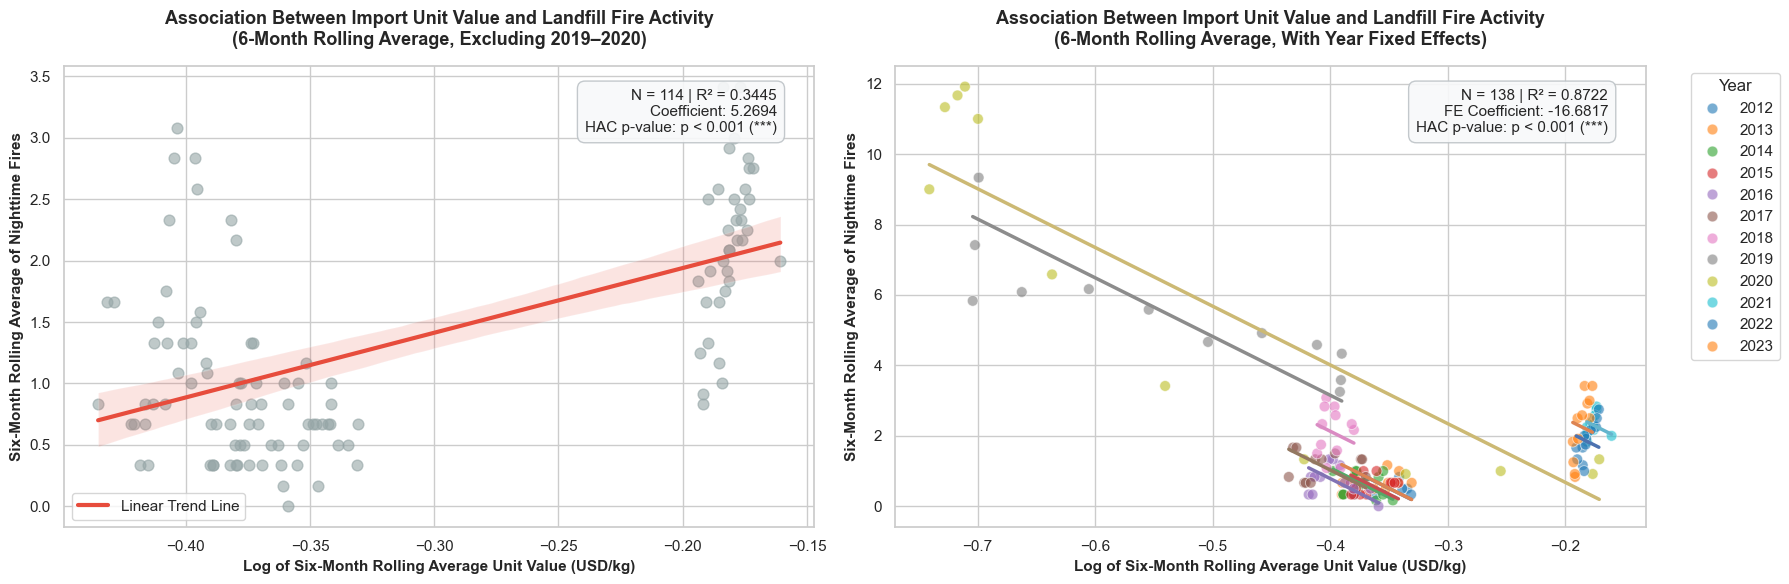

In [13]:
# ==========================================
# ROBUSTNESS CHECKS (HEADLINE LOG-SPECIFICATION + HAC)
# ==========================================
print("--- Running Reviewer Robustness Checks (6-Month Headline Spec, HAC Bandwidth = 6) ---")
w = 6
df_robust = df_cleaned.copy()

# 1. Calculate 6-month rolling averages
df_robust['Fire_Avg'] = df_robust[COL_FIRES].rolling(window=w).mean()
df_robust['Price_Avg'] = df_robust[COL_PRICE].rolling(window=w).mean()

# Drop NaNs generated by rolling average
df_robust.dropna(subset=['Price_Avg', 'Fire_Avg'], inplace=True)

# Apply headline log transformation to the rolling unit value
df_robust['log_Price_Avg'] = np.log(df_robust['Price_Avg'].replace(0, 0.1))

results_sensitivity = []

def get_sig(p):
    if p < 0.001: return "***"
    elif p < 0.01: return "**"
    elif p < 0.05: return "*"
    else: return "No"

# ---------------------------------------------------------
# TEST 1: "Without 2019-2020" Model (Headline Log Spec + HAC)
# ---------------------------------------------------------
df_no_covid = df_robust[~df_robust['year'].isin([2019, 2020])].copy()

mod_no_covid_hac = smf.ols('Fire_Avg ~ log_Price_Avg', data=df_no_covid).fit(cov_type='HAC', cov_kwds={'maxlags': w})
coef_1 = mod_no_covid_hac.params['log_Price_Avg']
p_1 = mod_no_covid_hac.pvalues['log_Price_Avg']
se_1 = mod_no_covid_hac.bse['log_Price_Avg']
ci_1 = mod_no_covid_hac.conf_int().loc['log_Price_Avg']

results_sensitivity.append({
    'Model': 'Excluding 2019-2020',
    'N': int(mod_no_covid_hac.nobs),
    'Coef': round(coef_1, 4),
    'HAC SE': round(se_1, 4),
    'HAC 95% CI': f"[{ci_1[0]:.4f}, {ci_1[1]:.4f}]",
    'HAC P-Val': round(p_1, 4),
    'HAC Sig': get_sig(p_1),
    'R2': round(mod_no_covid_hac.rsquared, 4)
})

# ---------------------------------------------------------
# TEST 2: Calendar-Year Fixed Effects (Full Sample, Log Spec + HAC)
# ---------------------------------------------------------
mod_fe_hac = smf.ols('Fire_Avg ~ log_Price_Avg + C(year)', data=df_robust).fit(cov_type='HAC', cov_kwds={'maxlags': w})
coef_2 = mod_fe_hac.params['log_Price_Avg']
p_2 = mod_fe_hac.pvalues['log_Price_Avg']
se_2 = mod_fe_hac.bse['log_Price_Avg']
ci_2 = mod_fe_hac.conf_int().loc['log_Price_Avg']

results_sensitivity.append({
    'Model': 'Full Sample&Year FE',
    'N': int(mod_fe_hac.nobs),
    'Coef': round(coef_2, 4),
    'HAC SE': round(se_2, 4),
    'HAC 95% CI': f"[{ci_2[0]:.4f}, {ci_2[1]:.4f}]",
    'HAC P-Val': round(p_2, 4),
    'HAC Sig': get_sig(p_2),
    'R2': round(mod_fe_hac.rsquared, 4)
})

# Print formatted summary table for your response letter / appendix
print("\n=========================================================================")
print("  REVIEWER SENSITIVITY TABLE (HEADLINE LOG SPECIFICATION + HAC)")
print("=========================================================================\n")
print(pd.DataFrame(results_sensitivity).to_string(index=False))
print("\n")

# ==========================================
# PLOTS (HEADLINE LOG SPECIFICATION + HAC)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.set_theme(style="whitegrid", rc={"axes.facecolor": "white", "grid.color": "#ededed"})

# ---------------------------------------------------------
# GRAPH 1: Excluding 2019-2020
# ---------------------------------------------------------
sns.regplot(
    x='log_Price_Avg', 
    y='Fire_Avg', 
    data=df_no_covid, 
    ax=axes[0],
    scatter_kws={'color': '#95a5a6', 'alpha': 0.6, 's': 60, 'label': 'Monthly Observations'},
    line_kws={'color': '#e74c3c', 'linewidth': 3, 'label': 'Linear Trend Line'}
)

axes[0].set_title("Association Between Import Unit Value and Landfill Fire Activity\n(6-Month Rolling Average, Excluding 2019–2020)", fontsize=13, fontweight='bold', pad=15)
axes[0].set_xlabel("Log of Six-Month Rolling Average Unit Value (USD/kg)", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Six-Month Rolling Average of Nighttime Fires", fontsize=11, fontweight='bold')

# Stats box for Graph 1
p_formatted = "p < 0.001" if p_1 < 0.001 else f"p = {p_1:.4f}"
sig_1 = "***" if p_1 < 0.001 else "**" if p_1 < 0.01 else "*" if p_1 < 0.05 else "No"
text_1 = (f"N = {int(mod_no_covid_hac.nobs)} | R² = {mod_no_covid_hac.rsquared:.4f}\n"
          f"Coefficient: {coef_1:.4f}\n"
          f"HAC p-value: {p_formatted} ({sig_1})")

axes[0].text(0.95, 0.95, text_1, transform=axes[0].transAxes, fontsize=11,
             verticalalignment='top', horizontalalignment='right',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', alpha=0.9, edgecolor='#bdc3c7'))
axes[0].legend(loc='lower left')

# ---------------------------------------------------------
# GRAPH 2: Year Fixed Effects with Individual Year Fit Lines
# ---------------------------------------------------------
# Generate predictions for the fixed effects model
df_robust['FE_Predict'] = mod_fe_hac.predict()

sns.scatterplot(
    x='log_Price_Avg', 
    y='Fire_Avg', 
    hue='year', 
    palette='tab10', 
    data=df_robust, 
    ax=axes[1], 
    alpha=0.6, 
    s=60
)

# Draw individual regression lines for each year to show the within-year slope
df_robust_sorted = df_robust.sort_values(['year', 'log_Price_Avg'])
for yr in df_robust_sorted['year'].unique():
    subset = df_robust_sorted[df_robust_sorted['year'] == yr]
    if len(subset) > 2:
        axes[1].plot(subset['log_Price_Avg'], subset['FE_Predict'], linewidth=2.5)

axes[1].set_title("Association Between Import Unit Value and Landfill Fire Activity\n(6-Month Rolling Average, With Year Fixed Effects)", fontsize=13, fontweight='bold', pad=15)
axes[1].set_xlabel("Log of Six-Month Rolling Average Unit Value (USD/kg)", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Six-Month Rolling Average of Nighttime Fires", fontsize=11, fontweight='bold')

# Stats box for Graph 2
p_formatted_2 = "p < 0.001" if p_2 < 0.001 else f"p = {p_2:.4f}"
sig_2 = "***" if p_2 < 0.001 else "**" if p_2 < 0.01 else "*" if p_2 < 0.05 else "No"
text_2 = (f"N = {int(mod_fe_hac.nobs)} | R² = {mod_fe_hac.rsquared:.4f}\n"
          f"FE Coefficient: {coef_2:.4f}\n"
          f"HAC p-value: {p_formatted_2} ({sig_2})")

axes[1].text(0.95, 0.95, text_2, transform=axes[1].transAxes, fontsize=11,
             verticalalignment='top', horizontalalignment='right',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', alpha=0.9, edgecolor='#bdc3c7'))

axes[1].legend(title='Year', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


[Year Fixed Effects WITHOUT 2019/2020 (Log Spec + HAC)]
Coefficient: 3.4988
HAC P-Value: 0.2500 (Not Significant)


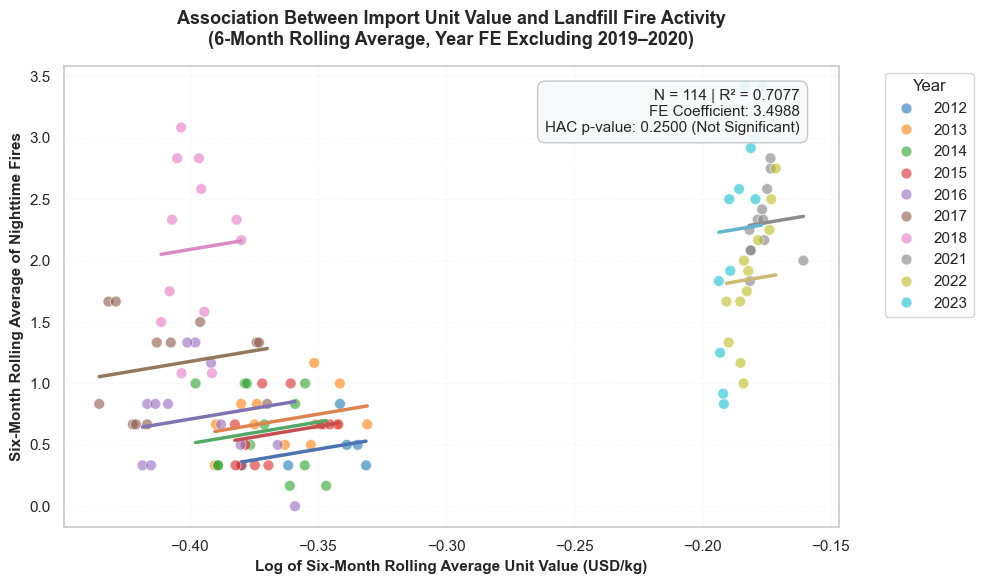

In [14]:
# =========================================================
# TEST: Year Fixed Effects WITHOUT 2019-2020 
# (Headline Log-Specification + HAC Inference)
# =========================================================
mod_ultimate_hac = smf.ols('Fire_Avg ~ log_Price_Avg + C(year)', data=df_no_covid).fit(cov_type='HAC', cov_kwds={'maxlags': w})

coef_ult = mod_ultimate_hac.params['log_Price_Avg']
p_ult = mod_ultimate_hac.pvalues['log_Price_Avg']
se_ult = mod_ultimate_hac.bse['log_Price_Avg']
ci_ult = mod_ultimate_hac.conf_int().loc['log_Price_Avg']

print("\n[Year Fixed Effects WITHOUT 2019/2020 (Log Spec + HAC)]")
print(f"Coefficient: {coef_ult:.4f}")
print(f"HAC P-Value: {p_ult:.4f} " + ("(Significant)" if p_ult < 0.05 else "(Not Significant)"))

# ==========================================
# VISUALIZING: Fixed Effects WITHOUT 2019-2020
# ==========================================
df_plot = df_no_covid.copy()
df_plot['FE_Predict_Ult'] = mod_ultimate_hac.predict()

plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid", rc={"axes.facecolor": "white", "grid.color": "#ededed"})

sns.scatterplot(
    x='log_Price_Avg', 
    y='Fire_Avg', 
    hue='year', 
    palette='tab10', 
    data=df_plot, 
    alpha=0.6, 
    s=60
)

# Draw regression lines for each year
df_plot_sorted = df_plot.sort_values(['year', 'log_Price_Avg'])
for yr in df_plot_sorted['year'].unique():
    subset = df_plot_sorted[df_plot_sorted['year'] == yr]
    if len(subset) > 2:
        plt.plot(subset['log_Price_Avg'], subset['FE_Predict_Ult'], linewidth=2.5)

# Formatting matching your previous styling
plt.title("Association Between Import Unit Value and Landfill Fire Activity\n(6-Month Rolling Average, Year FE Excluding 2019–2020)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Log of Six-Month Rolling Average Unit Value (USD/kg)", fontsize=11, fontweight='bold')
plt.ylabel("Six-Month Rolling Average of Nighttime Fires", fontsize=11, fontweight='bold')

# Statistical Box (Right-aligned, matching previous plots)
sig_ult = "***" if p_ult < 0.001 else "**" if p_ult < 0.01 else "*" if p_ult < 0.05 else "Not Significant"
text_str = (f"N = {int(mod_ultimate_hac.nobs)} | R² = {mod_ultimate_hac.rsquared:.4f}\n"
            f"FE Coefficient: {coef_ult:.4f}\n"
            f"HAC p-value: {p_ult:.4f} ({sig_ult})")

plt.gca().text(0.95, 0.95, text_str, transform=plt.gca().transAxes, fontsize=11,
               verticalalignment='top', horizontalalignment='right',
               bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', alpha=0.9, edgecolor='#bdc3c7'))

plt.legend(title='Year', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

In [15]:
# =========================================================
# SENSITIVITY RESULTS TABLE
# =========================================================
results_sensitivity = []

# 1. Add Test 1: Excluding 2019-2020 (Log Spec)
results_sensitivity.append({
    'Model': 'Excluding 2019-2020',
    'N': int(mod_no_covid_hac.nobs),
    'Coef': round(coef_1, 4),
    'HAC SE': round(se_1, 4),
    'HAC 95% CI': f"[{ci_1[0]:.4f}, {ci_1[1]:.4f}]",
    'HAC P-Val': round(p_1, 4),
    'HAC Sig': get_sig(p_1),
    'R2': round(mod_no_covid_hac.rsquared, 4)
})

# 2. Add Test 2: Full Sample & Year FE (Log Spec)
results_sensitivity.append({
    'Model': 'Full Sample & Year FE',
    'N': int(mod_fe_hac.nobs),
    'Coef': round(coef_2, 4),
    'HAC SE': round(se_2, 4),
    'HAC 95% CI': f"[{ci_2[0]:.4f}, {ci_2[1]:.4f}]",
    'HAC P-Val': round(p_2, 4),
    'HAC Sig': get_sig(p_2),
    'R2': round(mod_fe_hac.rsquared, 4)
})

# 3. Add Test 3: Excluding 2019-2020 + Year FE (Log Spec)
results_sensitivity.append({
    'Model': 'Excluding 2019-2020 + Year FE',
    'N': int(mod_ultimate_hac.nobs),
    'Coef': round(coef_ult, 4),
    'HAC SE': round(se_ult, 4),
    'HAC 95% CI': f"[{ci_ult[0]:.4f}, {ci_ult[1]:.4f}]",
    'HAC P-Val': round(p_ult, 4),
    'HAC Sig': get_sig(p_ult),
    'R2': round(mod_ultimate_hac.rsquared, 4)
})

# Print formatted summary table once cleanly
print("\n=========================================================================")
print("  SENSITIVITY ANALYSES RESULTS TABLE")
print("=========================================================================\n")
print(pd.DataFrame(results_sensitivity).to_string(index=False))
print("\n")

# --- EXPORT TO EXCEL ---
excel_output_path = "test_sensitivity_results.xlsx"
with pd.ExcelWriter(excel_output_path, engine="openpyxl") as writer:
    pd.DataFrame(results_sensitivity).to_excel(writer, sheet_name="Table_A2_sens", index=False)

print(f"Saved test result tables to '{excel_output_path}'")



  SENSITIVITY ANALYSES RESULTS TABLE

                        Model   N     Coef  HAC SE           HAC 95% CI  HAC P-Val HAC Sig     R2
          Excluding 2019-2020 114   5.2694  1.2018     [2.9139, 7.6249]       0.00     *** 0.3445
        Full Sample & Year FE 138 -16.6817  2.0893 [-20.7768, -12.5867]       0.00     *** 0.8722
Excluding 2019-2020 + Year FE 114   3.4988  3.0415    [-2.4624, 9.4600]       0.25      No 0.7077


Saved test result tables to 'test_sensitivity_results.xlsx'
